# Wstępna analiza danych tekstowych (EDA)
Cel: poznanie zbioru przed czyszczeniem – rozkład klas, braki, duplikaty, długość tekstów i ewentualne artefakty.

## 1. Biblioteki

In [20]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import datasets
from datasets import load_dataset

print("Python:", sys.version.split()[0])
for lib in (np, pd, matplotlib, datasets):
    print(f"{lib.__name__}: {lib.__version__}")

Python: 3.12.8
numpy: 2.5.4
pandas: 3.1.1
matplotlib: 3.11.2
datasets: 5.1.0


## 2. Wczytywanie danych

In [21]:
dataset = load_dataset("Mharis205/ai-text-detection-pile-cleaned")
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'generated', 'source'],
        num_rows: 577300
    })
    validation: Dataset({
        features: ['text', 'generated', 'source'],
        num_rows: 72162
    })
    test: Dataset({
        features: ['text', 'generated', 'source'],
        num_rows: 72164
    })
})

In [22]:
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

df = pd.concat([train_df, val_df, test_df], ignore_index=True)
del train_df, val_df, test_df

df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 721626 entries, 0 to 721625
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   text       721623 non-null  str  
 1   generated  721626 non-null  int64
 2   source     721626 non-null  str  
 3   split      721626 non-null  str  
dtypes: int64(1), str(3)
memory usage: 1.6 GB


In [23]:
df.head(10)

,text,generated,source,split
0,Droplets of water fell from the cracked ceilin...,0,human,train
1,He couldn't remember how many nights is it bee...,0,human,train
2,"There are lots of great places around you, tha...",1,ai,train
3,"BARACK OBAMA ""I am not proposing a big governm...",1,ai,train
4,Image copyright Getty Images Image caption Env...,0,human,train
5,eBay 2 Craigslist 3 Facebook Marketplace 4 Ama...,1,ai,train
6,"Image caption The attack happened in Daburah, ...",1,ai,train
7,This article is about the non-specific super-h...,1,ai,train
8,"By If you remember from a few months ago, we w...",1,ai,train
9,"I sat in my rolling chair, spinning around for...",0,human,train


### Obserwacje

- Zbiór ma 721 626 tekstów podzielonych na train, validation i test, mniej więcej w proporcji 80/10/10
- Kolumna `text` ma 3 brakujące wartości (NaN), pozostałe kolumny są kompletne.
- W tekstach widać pozostałości po pobieraniu tekstów np. "Image caption"

## 3. Rozkład klas

In [24]:
print(df["split"].value_counts())
pd.crosstab(df["split"], df["generated"], normalize="index")

split
train         577300
test           72164
validation     72162
Name: count, dtype: int64


generated,0,1
split,,
test,0.499723,0.500277
train,0.500139,0.499861
validation,0.499169,0.500831


In [25]:
pd.crosstab(df["source"], df["generated"])

generated,0,1
source,,
ai,0,360813
human,360813,0


### Obserwacje

- Klasy są idealnie zbalansowane: po 360 813 tekstów ludzkich i AI. W każdym splicie proporcja jest bardzo bliska 50/50.
- Kolumna `source` jest kopią etykiety (`human` = 0, `ai` = 1), więc nie może być cechą modelu, bo zdradzałaby mu odpowiedź.

## 4. Braki i puste teksty

In [26]:
empty = df["text"].str.strip() == ""
print("Puste teksty:", empty.sum())

Puste teksty: 0


In [27]:
print("Brakujące teksty (NaN):", df["text"].isna().sum())
df[df["text"].isna()]

Brakujące teksty (NaN): 3


,text,generated,source,split
663438,NaN,1,ai,test
706197,NaN,0,human,test
714570,NaN,1,ai,test


### Obserwacje

- Nie ma pustych tekstów, ale 3 teksty mają wartość NaN – wszystkie w splicie test (2 AI, 1 human). Zostaną usunięte przy czyszczeniu.

## 5. Duplikaty

In [28]:
duplicates = df.duplicated(subset="text", keep="first")
print("Nadmiarowe kopie:", duplicates.sum())
print(df[duplicates]["generated"].value_counts())

Nadmiarowe kopie: 29
generated
1    27
0     2
Name: count, dtype: int64


In [29]:
all_copies = df[df.duplicated(subset="text", keep=False)]

labels_per_text = all_copies.groupby("text")["generated"].nunique()
print("Teksty z dwiema różnymi etykietami:", (labels_per_text > 1).sum())

splits_per_text = all_copies.groupby("text")["split"].nunique()
print("Teksty występujące w więcej niż jednym splicie:", (splits_per_text > 1).sum())

Teksty z dwiema różnymi etykietami: 1
Teksty występujące w więcej niż jednym splicie: 13


In [30]:
all_copies.sort_values("text")[["text", "generated", "split"]].head(20)

,text,generated,split
72208,! network error There was an error generating ...,1,train
597359,! network error There was an error generating ...,1,validation
158793,1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 1...,1,train
225860,1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 1...,1,train
661715,1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 1...,1,test
289221,1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 1...,0,train
396800,1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 1...,1,train
182156,1. Denial 2. Anger 3. Bargaining 4. Depression...,1,train
618535,1. Denial 2. Anger 3. Bargaining 4. Depression...,1,validation
429228,1. Great Pyramid of Giza 2. Hanging Gardens of...,1,train


### Obserwacje

- `duplicated()` znalazło 29 nadmiarowych kopii, ale 2 z nich to wiersze z NaN (pandas traktuje NaN jako równe sobie). Prawdziwych powtórzonych tekstów jest 27 (26 AI, 1 human).
- 1 tekst ma jednocześnie etykietę human i AI.
- 13 tekstów występuje w więcej niż jednym splicie, więc mogłyby trafić jednocześnie do zbioru treningowego i testowego.
- Duplikatów jest bardzo mało (ok. 0,004% zbioru), ale i tak zostaną usunięte przy czyszczeniu.

## 6. Długość tekstów

In [31]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.count(r"\S+")

df.groupby("generated")[["n_chars", "n_words"]].describe().T

generated                  0              1
n_chars count  360812.000000  360811.000000
        mean     2409.189126    2221.701176
        std      4022.092627    1676.758765
        min        13.000000       4.000000
        25%       953.000000     646.000000
        50%       985.000000    1790.000000
        75%      2373.000000    3963.000000
        max    277466.000000    6740.000000
n_words count  360812.000000  360811.000000
        mean      403.455911     389.006330
        std       625.375178     295.045189
        min         4.000000       1.000000
        25%       172.000000     114.000000
        50%       187.000000     309.000000
        75%       394.000000     694.000000
        max     41373.000000    1024.000000

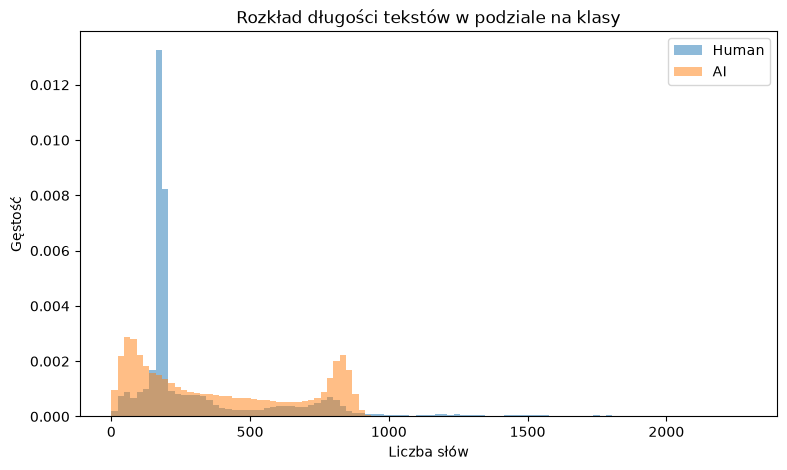

In [32]:
human = df[df["generated"] == 0]["n_words"]
ai = df[df["generated"] == 1]["n_words"]
limit = df["n_words"].quantile(0.99)

plt.figure(figsize=(9, 5))
plt.hist(human, bins=100, range=(0, limit), alpha=0.5, density=True, label="Human")
plt.hist(ai, bins=100, range=(0, limit), alpha=0.5, density=True, label="AI")
plt.xlabel("Liczba słów")
plt.ylabel("Gęstość")
plt.title("Rozkład długości tekstów w podziale na klasy")
plt.legend()
plt.savefig("../figures/text_01_length_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [33]:
print("Teksty AI z dokładnie 1024 słowami:", (ai == 1024).sum())
print("Teksty human dłuższe niż 1024 słowa:", (human > 1024).sum())

Teksty AI z dokładnie 1024 słowami: 1
Teksty human dłuższe niż 1024 słowa: 23373


### Obserwacje

- Teksty AI mają maksymalnie 1024 słowa (6740 znaków), a teksty ludzkie nawet 41 373 słowa. Prawdopodobnie przy generowaniu był limit długości.
- Rozkłady długości obu klas mają inny kształt: mediana to 187 słów dla tekstów ludzkich i 309 dla AI. Co najmniej ćwierć tekstów ludzkich ma prawie taką samą długość (953–985 znaków), co sugeruje, że były ucinane do ok. 1000 znaków.
- Są bardzo krótkie teksty (minimum 4 słowa u ludzi i 1 słowo u AI).
- Długość tekstu mogłaby więc zdradzać klasę przez sposób przygotowania zbioru, a nie przez to, czy tekst napisała AI. Trzeba to uwzględnić przy czyszczeniu.